# NetGuard AI
## 01 — Data Understanding

### Objective

The objective of this notebook is to understand the structure,
quality, and characteristics of the network traffic dataset before
applying machine learning algorithms.

We will investigate:

1. Dataset dimensions
2. Individual records and features
3. Data types
4. Target variable
5. Class distribution
6. Feature categories
7. Basic descriptive statistics
8. Missing and infinite values
9. Duplicate records
10. Initial observations

The analysis in this notebook will guide the subsequent stages of
feature selection and model development.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv('../data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')
df

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225740,61374,61,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225741,61378,72,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225742,61375,75,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225743,61323,48,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [4]:
df.shape

(225745, 79)

In [5]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0    Destination Port             225745 non-null  int64  
 1    Flow Duration                225745 non-null  int64  
 2    Total Fwd Packets            225745 non-null  int64  
 3    Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets   225745 non-null  int64  
 5    Total Length of Bwd Packets  225745 non-null  int64  
 6    Fwd Packet Length Max        225745 non-null  int64  
 7    Fwd Packet Length Min        225745 non-null  int64  
 8    Fwd Packet Length Mean       225745 non-null  float64
 9    Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max         225745 non-null  int64  
 11   Bwd Packet Length Min        225745 non-null  int64  
 12   Bwd Packet Length Mean       225745 non-nul

In [7]:
df.describe().T

d:\Network_Traffic_Threat_Analysis\venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
d:\Network_Traffic_Threat_Analysis\venv\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
Destination Port,225745.0,8.879619e+03,1.975465e+04,0.0,80.0,80.0,80.0,65532.0
Flow Duration,225745.0,1.624165e+07,3.152437e+07,-1.0,71180.0,1452333.0,8805237.0,119999937.0
Total Fwd Packets,225745.0,4.874916e+00,1.542287e+01,1.0,2.0,3.0,5.0,1932.0
Total Backward Packets,225745.0,4.572775e+00,2.175536e+01,0.0,1.0,4.0,5.0,2942.0
Total Length of Fwd Packets,225745.0,9.394633e+02,3.249403e+03,0.0,26.0,30.0,63.0,183012.0
...,...,...,...,...,...,...,...,...
Active Min,225745.0,1.776201e+05,7.842602e+05,0.0,0.0,0.0,1862.0,100000000.0
Idle Mean,225745.0,1.032214e+07,2.185303e+07,0.0,0.0,0.0,8239725.0,120000000.0
Idle Std,225745.0,3.611943e+06,1.275689e+07,0.0,0.0,0.0,0.0,65300000.0
Idle Max,225745.0,1.287813e+07,2.692126e+07,0.0,0.0,0.0,8253838.0,120000000.0


In [8]:
# Check attack distribution

df[" Label"].value_counts()

 Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

In [9]:
df.columns

Index([' Destination Port', ' Flow Duration', ' Total Fwd Packets',
       ' Total Backward Packets', 'Total Length of Fwd Packets',
       ' Total Length of Bwd Packets', ' Fwd Packet Length Max',
       ' Fwd Packet Length Min', ' Fwd Packet Length Mean',
       ' Fwd Packet Length Std', 'Bwd Packet Length Max',
       ' Bwd Packet Length Min', ' Bwd Packet Length Mean',
       ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s',
       ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min',
       'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max',
       ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std',
       ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags',
       ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length',
       ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s',
       ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean',
       ' Packet Length Std', ' Packet Length Variance', '

In [10]:
# Clean column names

df.columns = df.columns.str.strip()

In [11]:
df.columns

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Co

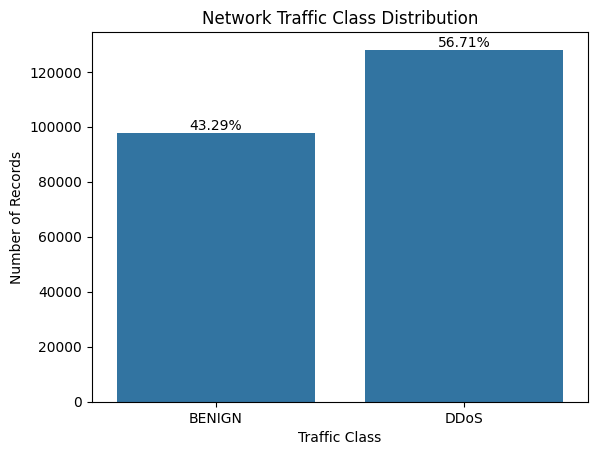

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
ax=sns.countplot(x='Label', data=df)
plt.bar_label(ax.containers[0], [f'{(v/len(df))*100:.2f}%' for v in df['Label'].value_counts()[::-1]])
plt.title("Network Traffic Class Distribution")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

In [13]:
# Handle infinity values

df = df.replace([np.inf, -np.inf], np.nan)



In [14]:
df.isnull().sum().sum()

np.int64(68)

In [15]:
df.shape

(225745, 79)

In [16]:
df.isnull().sum().sort_values(ascending=False)

Flow Bytes/s                   34
Flow Packets/s                 34
Flow Duration                   0
Total Backward Packets          0
Total Length of Fwd Packets     0
                               ..
Idle Mean                       0
Idle Std                        0
Idle Max                        0
Idle Min                        0
Label                           0
Length: 79, dtype: int64

In [17]:
df.dropna(inplace=True) 

In [18]:
df.shape

(225711, 79)

In [19]:
# Check duplicates and drop them if any
print("Duplicates:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

Duplicates: 2629


In [20]:
df.shape

(223082, 79)

In [21]:
target_column = "Label"

print("Target column:", target_column)
print("Unique target values:")
print(df[target_column].unique())

Target column: Label
Unique target values:
['BENIGN' 'DDoS']


In [22]:
df[target_column].value_counts(normalize=True) * 100

Label
DDoS      57.38428
BENIGN    42.61572
Name: proportion, dtype: float64

In [23]:
class_distribution = df["Label"].value_counts(normalize=True) * 100

print(class_distribution.round(2))

Label
DDoS      57.38
BENIGN    42.62
Name: proportion, dtype: float64


In [24]:
feature_columns = df.columns.drop("Label")

print("Total columns :", len(df.columns))
print("Feature count :", len(feature_columns))
print("Target column :", "Label")

Total columns : 79
Feature count : 78
Target column : Label


In [25]:
df.dtypes.value_counts()

int64      54
float64    24
object      1
Name: count, dtype: int64

In [26]:
numeric_features = df.select_dtypes(include=np.number).columns

categorical_features = df.select_dtypes(exclude=np.number).columns

print("Numeric features:", len(numeric_features))
print("Non-numeric columns:", len(categorical_features))

print("\nNon-numeric columns:")
print(categorical_features.tolist())

Numeric features: 78
Non-numeric columns: 1

Non-numeric columns:
['Label']


In [27]:
for i, feature in enumerate(feature_columns, start=1):
    print(f"{i:2}. {feature}")

 1. Destination Port
 2. Flow Duration
 3. Total Fwd Packets
 4. Total Backward Packets
 5. Total Length of Fwd Packets
 6. Total Length of Bwd Packets
 7. Fwd Packet Length Max
 8. Fwd Packet Length Min
 9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd Header Length
36. Bwd Header Length
37. Fwd Packets/s
38. Bwd Packets/s
39. Min Packet Length
40. Max Packet Length
41. Packet Length Mean
42. Packet Length Std
43. Packet Length Variance
44. FIN Flag Count
45. SYN Flag Count
46. RST Flag Count
47. PSH Flag Count
48. ACK Flag Count
49. 

In [28]:
# constant features

unique_counts = df[numeric_features].nunique()

constant_features = unique_counts[unique_counts <= 1]

print("Constant features:")
print(constant_features)

Constant features:
Bwd PSH Flags           1
Fwd URG Flags           1
Bwd URG Flags           1
CWE Flag Count          1
Fwd Avg Bytes/Bulk      1
Fwd Avg Packets/Bulk    1
Fwd Avg Bulk Rate       1
Bwd Avg Bytes/Bulk      1
Bwd Avg Packets/Bulk    1
Bwd Avg Bulk Rate       1
dtype: int64


In [29]:
print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nInfinite values:")
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget classes:")
print(df["Label"].value_counts())

Final dataset shape: (223082, 79)

Missing values:
0

Infinite values:
0

Duplicate rows:
0

Target classes:
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64


In [30]:
df.to_csv("netguard_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


## Conclusion

The dataset was checked for common data-quality problems.

The analysis confirmed that:

- There are no missing values.
- There are no infinite values.
- There are no duplicate records.
- The target variable contains the expected BENIGN and DDoS classes.
- Numerical traffic features are ready for further analysis.

The cleaned dataset has been saved as `netguard_cleaned.csv`.

The next step is exploratory data analysis to understand the
distribution of network traffic features and the differences
between BENIGN and DDoS traffic.